<a href="https://colab.research.google.com/github/nitha604/news-article-categorisation/blob/main/03_preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Install required libraries
# nltk  --> Natural Language Toolkit (classic NLP library)
# spacy --> Modern, fast NLP library (we'll use it for lemmatisation)

!pip install nltk spacy tqdm -q
print("Libraries installed! ")

# Download the spaCy English model
# 'en_core_web_sm' is a small (~12 MB) English model -- perfect for our use case
!python -m spacy download en_core_web_sm
print("spaCy English model downloaded! ")

Libraries installed! 
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 35.2 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
spaCy English model downloaded! 


In [1]:
# ─── Import Libraries ───────────────────────────────────────────────────────
import re                          # Regular expressions (for pattern matching)
import string                      # String utilities
import pandas as pd                # DataFrames
import numpy as np                 # Numerical operations
import matplotlib.pyplot as plt    # Plotting
import warnings
warnings.filterwarnings('ignore')

# NLTK
import nltk
nltk.download('stopwords', quiet=True)   # Common English stopwords list
nltk.download('punkt', quiet=True)       # Tokenizer
nltk.download('punkt_tab', quiet=True)   # Newer tokenizer data
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

# spaCy
import spacy
nlp = spacy.load('en_core_web_sm')  # Load the English language model

# tqdm -- shows a nice progress bar (very useful!)
from tqdm.notebook import tqdm
tqdm.pandas()

print("All libraries imported successfully! ")
print(f"\nspaCy version  : {spacy.__version__}")
print(f"NLTK version   : {nltk.__version__}")
print(f"Pandas version : {pd.__version__}")

All libraries imported successfully! 

spaCy version  : 3.8.16
NLTK version   : 3.9.1
Pandas version : 2.2.3


In [2]:
# ─── Mount Google Drive & Load Data ─────────────────────────────────────────
from google.colab import drive
drive.mount('/content/drive')

DATA_PATH    = '/content/drive/MyDrive/news_project/raw_data.csv'
SAVE_PATH    = '/content/drive/MyDrive/news_project/cleaned_data.csv'

df = pd.read_csv(DATA_PATH)

print(f"Dataset loaded! ")
print(f"Shape : {df.shape}")
print(f"\nColumn names : {df.columns.tolist()}")
print(f"\nCategory distribution:")
print(df['category'].value_counts())
print(f"\nSample row:")
df.head(2)

Mounted at /content/drive
Dataset loaded! 
Shape : (2040, 2)

Column names : ['text', 'category']

Category distribution:
category
Sports        1000
Technology    1000
Education       20
Politics        20
Name: count, dtype: int64

Sample row:


,text,category
0,Barrera outslugs Morales for title Somehow Mar...,Sports
1,Ajax finally comes to terms with Trabelsi Amst...,Sports


In [3]:
def lowercase(text):
    """Convert all characters to lowercase."""
    return text.lower()


# ─── Before / After Example ──────────────────────────────────────────────────
example = "IPL: Mumbai Indians Beat Chennai Super Kings by 20 Runs!"
print("BEFORE:", example)
print("AFTER: ", lowercase(example))

print("\n--- Another example ---")
isro_example = "ISRO Successfully Launches Chandrayaan-3 Towards The Moon!"
print("BEFORE:", isro_example)
print("AFTER: ", lowercase(isro_example))

BEFORE: IPL: Mumbai Indians Beat Chennai Super Kings by 20 Runs!
AFTER:  ipl: mumbai indians beat chennai super kings by 20 runs!

--- Another example ---
BEFORE: ISRO Successfully Launches Chandrayaan-3 Towards The Moon!
AFTER:  isro successfully launches chandrayaan-3 towards the moon!


In [4]:
def remove_punct_numbers(text):
    """Remove all characters that are not lowercase letters or whitespace."""
    text = re.sub(r'[^a-z\s]', '', text)
    # Also remove extra whitespace that might be created
    text = re.sub(r'\s+', ' ', text).strip()
    return text


# ─── Chain from previous step ────────────────────────────────────────────────
example2 = lowercase(example)   # result from Step 1
print("BEFORE:", example2)
print("AFTER: ", remove_punct_numbers(example2))

print("\n--- ISRO example ---")
isro_ex2 = lowercase(isro_example)
print("BEFORE:", isro_ex2)
print("AFTER: ", remove_punct_numbers(isro_ex2))

print("\n--- Politics example ---")
politics_ex = "PM Modi Announces ₹10,000 Crore Package for NEP 2020 Implementation!"
print("BEFORE:", politics_ex)
print("AFTER: ", remove_punct_numbers(lowercase(politics_ex)))

BEFORE: ipl: mumbai indians beat chennai super kings by 20 runs!
AFTER:  ipl mumbai indians beat chennai super kings by runs

--- ISRO example ---
BEFORE: isro successfully launches chandrayaan-3 towards the moon!
AFTER:  isro successfully launches chandrayaan towards the moon

--- Politics example ---
BEFORE: PM Modi Announces ₹10,000 Crore Package for NEP 2020 Implementation!
AFTER:  pm modi announces crore package for nep implementation


In [5]:
# Load NLTK's English stopword list
stop_words = set(stopwords.words('english'))
print(f"Total stopwords in NLTK's list: {len(stop_words)}")
print(f"\nFirst 30 stopwords (sorted):")
print(sorted(list(stop_words))[:30])


def remove_stopwords(text):
    """Remove stopwords from text."""
    words = text.split()
    filtered = [w for w in words if w not in stop_words]
    return ' '.join(filtered)


# ─── Chain from previous steps ───────────────────────────────────────────────
example3 = remove_punct_numbers(example2)   # result from Step 2

print("\n" + "="*60)
print("BEFORE:", example3)
cleaned = remove_stopwords(example3)
print("AFTER: ", cleaned)

removed_words = set(example3.split()) - set(cleaned.split())
print(f"\nWords removed ({len(removed_words)}): {removed_words}")

print("\n--- NEP Education example ---")
edu_ex = "the government announced that the new education policy will be implemented in all states"
print("BEFORE:", edu_ex)
print("AFTER: ", remove_stopwords(edu_ex))

Total stopwords in NLTK's list: 198

First 30 stopwords (sorted):
['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been', 'before', 'being', 'below', 'between', 'both', 'but', 'by', 'can', 'couldn', "couldn't"]

BEFORE: ipl mumbai indians beat chennai super kings by runs
AFTER:  ipl mumbai indians beat chennai super kings runs

Words removed (1): {'by'}

--- NEP Education example ---
BEFORE: the government announced that the new education policy will be implemented in all states
AFTER:  government announced new education policy implemented states


In [6]:
# spaCy model is already loaded as 'nlp' from the imports cell

def lemmatize(text):
    """Lemmatise text using spaCy — reduce words to their root/base form."""
    doc = nlp(text)
    return ' '.join([token.lemma_ for token in doc])


# ─── Chain from previous steps ───────────────────────────────────────────────
example4 = remove_stopwords(example3)   # result from Step 3

print("BEFORE:", example4)
print("AFTER: ", lemmatize(example4))

print("\n--- Word-by-word lemmatisation demo ---")
demo_words = "scientists are running experiments technologies developing winning studies"
doc = nlp(demo_words)
print(f"{'Original':<15} {'Lemma':<15}")
print("-" * 30)
for token in doc:
    print(f"{token.text:<15} {token.lemma_:<15}")

print("\n--- Technology example ---")
tech_ex = "researchers developing advanced technologies using machine learning algorithms"
print("BEFORE:", tech_ex)
print("AFTER: ", lemmatize(tech_ex))

BEFORE: ipl mumbai indians beat chennai super kings runs
AFTER:  ipl mumbai indians beat chennai super king run

--- Word-by-word lemmatisation demo ---
Original        Lemma          
------------------------------
scientists      scientist      
are             be             
running         run            
experiments     experiment     
technologies    technology     
developing      develop        
winning         win            
studies         study          

--- Technology example ---
BEFORE: researchers developing advanced technologies using machine learning algorithms
AFTER:  researcher develop advanced technology use machine learning algorithm


In [7]:
def preprocess(text):
    """
    Full NLP preprocessing pipeline:
      1. Handle missing values
      2. Lowercase
      3. Remove punctuation & numbers
      4. Remove stopwords
      5. Lemmatise

    Args:
        text (str): Raw input text

    Returns:
        str: Cleaned, preprocessed text
    """
    # Handle NaN / None / non-string values
    if not isinstance(text, str) or len(text.strip()) == 0:
        return ''

    # Step 1: Lowercase
    text = text.lower()

    # Step 2: Remove punctuation and numbers
    text = re.sub(r'[^a-z\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()

    # Step 3: Remove stopwords
    text = ' '.join([w for w in text.split() if w not in stop_words])

    # Step 4: Lemmatise using spaCy
    doc = nlp(text)
    text = ' '.join([token.lemma_ for token in doc if token.lemma_.strip()])

    return text


# Quick test
test_sentence = "India's ISRO Scientists are Planning New Moon Missions in 2025!"
print("Input :", test_sentence)
print("Output:", preprocess(test_sentence))

print("\n--- Edge case: NaN value ---")
print("Input : None")
print("Output:", repr(preprocess(None)))

print("\n Pipeline function is working correctly!")

Input : India's ISRO Scientists are Planning New Moon Missions in 2025!
Output: indias isro scientist plan new moon mission

--- Edge case: NaN value ---
Input : None
Output: ''

 Pipeline function is working correctly!


In [8]:
# ─── Before/After comparison for 5 representative examples ───────────────────
sample_texts = [
    {
        'Category': ' Sports',
        'Before': 'Rohit Sharma smashed 3 sixes in the final over to win the T20 match against Australia!'
    },
    {
        'Category': ' Technology',
        'Before': 'ISRO\'s Chandrayaan-3 successfully landed on the Moon\'s south pole on 23rd August 2023.'
    },
    {
        'Category': ' Education',
        'Before': 'The National Education Policy (NEP) 2020 aims to transform India\'s education system by 2030.'
    },
    {
        'Category': ' Politics',
        'Before': 'PM Modi addressed 50,000+ supporters at a rally in Ahmedabad ahead of the elections.'
    },
    {
        'Category': ' Technology',
        'Before': 'Google\'s DeepMind researchers are developing new AI models that can solve complex mathematical problems.'
    },
]

# Apply preprocessing to each example
for item in sample_texts:
    item['After'] = preprocess(item['Before'])
    item['Words Before'] = len(item['Before'].split())
    item['Words After'] = len(item['After'].split())
    item['Reduction %'] = f"{(1 - item['Words After']/item['Words Before'])*100:.0f}%"

comparison_df = pd.DataFrame(sample_texts)

# Display nicely
pd.set_option('display.max_colwidth', 80)
print("=" * 120)
print("BEFORE/AFTER COMPARISON")
print("=" * 120)
for _, row in comparison_df.iterrows():
    print(f"\n Category : {row['Category']}")
    print(f"   BEFORE   : {row['Before']}")
    print(f"   AFTER    : {row['After']}")
    print(f"   Words    : {row['Words Before']} → {row['Words After']} (reduced by {row['Reduction %']})")
    print("-" * 120)

# Also show as DataFrame
print("\n Summary Table:")
comparison_df[['Category', 'Words Before', 'Words After', 'Reduction %']]

BEFORE/AFTER COMPARISON

 Category :  Sports
   BEFORE   : Rohit Sharma smashed 3 sixes in the final over to win the T20 match against Australia!
   AFTER    : rohit sharma smash six final win match australia
   Words    : 16 → 8 (reduced by 50%)
------------------------------------------------------------------------------------------------------------------------

 Category :  Technology
   BEFORE   : ISRO's Chandrayaan-3 successfully landed on the Moon's south pole on 23rd August 2023.
   AFTER    : isros chandrayaan successfully land moon south pole rd august
   Words    : 13 → 9 (reduced by 31%)
------------------------------------------------------------------------------------------------------------------------

 Category :  Education
   BEFORE   : The National Education Policy (NEP) 2020 aims to transform India's education system by 2030.
   AFTER    : national education policy nep aim transform indias education system
   Words    : 14 → 9 (reduced by 36%)
--------------------

,Category,Words Before,Words After,Reduction %
0,Sports,16,8,50%
1,Technology,13,9,31%
2,Education,14,9,36%
3,Politics,14,8,43%
4,Technology,14,11,21%


In [9]:
print(" Applying preprocessing to the entire dataset...")
print(f"   Total rows: {len(df):,}")

from tqdm.notebook import tqdm
tqdm.pandas()

# Apply with a progress bar
df['clean_text'] = df['text'].progress_apply(preprocess)

print("\nDone! ")
print(f"\nRows processed      : {len(df):,}")
print(f"Empty results (NaN) : {df['clean_text'].isna().sum()}")
print(f"Empty string rows   : {(df['clean_text'] == '').sum()}")

print("\n Sample output (first 3 rows):")
print(df[['text', 'clean_text']].head(3).to_string())

 Applying preprocessing to the entire dataset...
   Total rows: 2,040


  0%|          | 0/2040 [00:00<?, ?it/s]


Done! 

Rows processed      : 2,040
Empty results (NaN) : 0
Empty string rows   : 0

 Sample output (first 3 rows):
                                                                                                                                                                                                                                                                   text                                                                                                                                                                       clean_text
0                                   Barrera outslugs Morales for title Somehow Marco Antonio Barrera and Erik Morales duplicated, and perhaps even surpassed, the action and drama of their all-time great first battle, which took place four years ago at 122 pounds.     barrera outslug morale title somehow marco antonio barrera erik morale duplicate perhaps even surpass action drama alltime great first battle take place four year ago pound
1

 Text Length Summary by Category:
  category  Avg_Words_Before  Avg_Words_After  Avg_Reduction_Pct  Article_Count
 Education               9.7              7.6               20.8             20
  Politics               9.6              7.8               17.9             20
    Sports              37.9             23.7               36.8           1000
Technology              37.4             24.6               33.3           1000


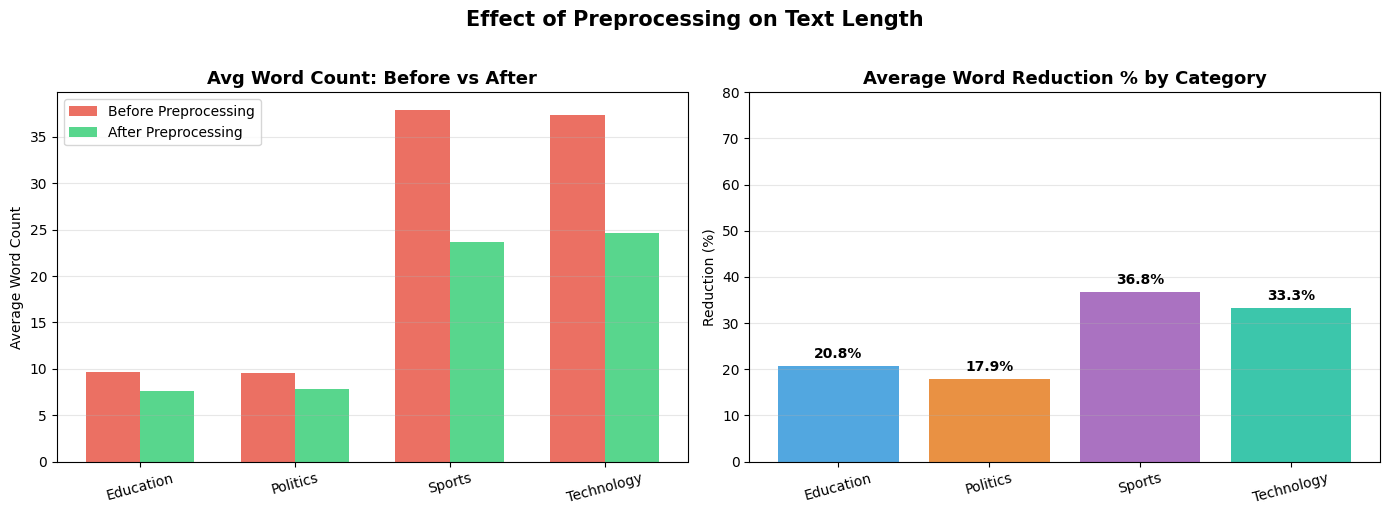


 Plot saved to Drive! 


In [10]:
# ─── Compute word counts ─────────────────────────────────────────────────────
df['word_count_before'] = df['text'].apply(lambda x: len(str(x).split()))
df['word_count_after']  = df['clean_text'].apply(lambda x: len(str(x).split()))
df['reduction_pct']     = ((df['word_count_before'] - df['word_count_after']) /
                            df['word_count_before'] * 100).round(1)

# ─── Summary per category ────────────────────────────────────────────────────
summary = df.groupby('category').agg(
    Avg_Words_Before = ('word_count_before', 'mean'),
    Avg_Words_After  = ('word_count_after',  'mean'),
    Avg_Reduction_Pct= ('reduction_pct',     'mean'),
    Article_Count    = ('text',              'count')
).round(1).reset_index()

print(" Text Length Summary by Category:")
print(summary.to_string(index=False))

# ─── Plot ────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

categories = summary['category'].tolist()
x = range(len(categories))
width = 0.35

# Bar chart: before vs after
axes[0].bar([i - width/2 for i in x], summary['Avg_Words_Before'], width,
            label='Before Preprocessing', color='#e74c3c', alpha=0.8)
axes[0].bar([i + width/2 for i in x], summary['Avg_Words_After'], width,
            label='After Preprocessing', color='#2ecc71', alpha=0.8)
axes[0].set_title('Avg Word Count: Before vs After', fontsize=13, fontweight='bold')
axes[0].set_xticks(list(x))
axes[0].set_xticklabels(categories, rotation=15)
axes[0].set_ylabel('Average Word Count')
axes[0].legend()
axes[0].grid(axis='y', alpha=0.3)

# Bar chart: reduction %
bars = axes[1].bar(categories, summary['Avg_Reduction_Pct'],
                   color=['#3498db', '#e67e22', '#9b59b6', '#1abc9c'], alpha=0.85)
axes[1].set_title('Average Word Reduction % by Category', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Reduction (%)')
axes[1].set_xticklabels(categories, rotation=15)
axes[1].set_ylim(0, 80)
axes[1].grid(axis='y', alpha=0.3)
for bar, val in zip(bars, summary['Avg_Reduction_Pct']):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                 f'{val}%', ha='center', va='bottom', fontweight='bold')

plt.suptitle('Effect of Preprocessing on Text Length', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/news_project/preprocessing_length_analysis.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("\n Plot saved to Drive! ")

In [11]:
# ─── Drop analysis-only columns before saving ────────────────────────────────
cols_to_drop = ['word_count_before', 'word_count_after', 'reduction_pct']
save_df = df.drop(columns=[c for c in cols_to_drop if c in df.columns])

# ─── Save to Google Drive ─────────────────────────────────────────────────────
save_df.to_csv(SAVE_PATH, index=False)

print(f" Cleaned data saved successfully!")
print(f"    Location : {SAVE_PATH}")
print(f"    Shape    : {save_df.shape}")
print(f"    Columns  : {save_df.columns.tolist()}")

# ─── Final verification ───────────────────────────────────────────────────────
verify_df = pd.read_csv(SAVE_PATH)
print(f"\n Verification (re-read from file):")
print(f"   Shape matches: {verify_df.shape == save_df.shape} ")
print(f"\n Sample of saved data:")
print(verify_df[['text', 'clean_text', 'category']].head(3).to_string())

 Cleaned data saved successfully!
    Location : /content/drive/MyDrive/news_project/cleaned_data.csv
    Shape    : (2040, 3)
    Columns  : ['text', 'category', 'clean_text']

 Verification (re-read from file):
   Shape matches: True 

 Sample of saved data:
                                                                                                                                                                                                                                                                   text                                                                                                                                                                       clean_text category
0                                   Barrera outslugs Morales for title Somehow Marco Antonio Barrera and Erik Morales duplicated, and perhaps even surpassed, the action and drama of their all-time great first battle, which took place four years ago at 122 pounds.     barrera outslug moral